In [1]:
import numpy as np
import scipy.io
import pandas as pd
import anndata as ad

# ── 1. Load CellOracle A matrix ────────────────────────────────────────────────
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
CO   = f"{BASE}/cell_oracle_run/cell_oracle_global_A"

A      = np.load(f"{CO}/A_celloracle.npy")
A_genes = np.load(f"{CO}/A_genes.npy", allow_pickle=True)
A_tfs   = np.load(f"{CO}/A_tfs.npy",   allow_pickle=True)
print("A shape:", A.shape)  # (n_tfs, n_genes)

# ── 2. Load RNA ─────────────────────────────────────────────────────────────────
adata      = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names = list(adata.var_names)
g2i        = {g: i for i, g in enumerate(gene_names)}
X_full     = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

# ── 3. Align A to RNA gene space ────────────────────────────────────────────────
gene_mask = np.array([g in g2i for g in A_genes])
A         = A[:, gene_mask]
A_genes   = A_genes[gene_mask]

# Keep only TFs that are also in the gene list
tf_in_genes_mask = np.array([t in set(A_genes) for t in A_tfs])
A     = A[tf_in_genes_mask, :]
A_tfs = A_tfs[tf_in_genes_mask]

print("A aligned:", A.shape)

# Gene/TF indices into the full RNA matrix
gene_idx = np.array([g2i[g] for g in A_genes])
sub_g2i  = {g: i for i, g in enumerate(A_genes)}
tf_idx   = np.array([sub_g2i[t] for t in A_tfs])

X     = X_full[:, gene_idx]   # (cells, n_genes_kept)
X_TF  = X[:, tf_idx]          # (cells, n_tfs_kept)

# ── 4. Build M (genes x TFs), aligned to A_genes / A_tfs ──────────────────────
peak_tf  = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()   # (peaks, n_motif_tfs)
tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
assert peak_tf.shape[1] == len(tf_names), "peak_tf col mismatch"

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")  # cols: peak, gene
peaks     = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()

peak_to_idx = {p: i for i, p in enumerate(peaks)}

# Build sparse peak x gene matrix (only for genes in A_genes)
from scipy.sparse import lil_matrix
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G))
for _, row in peak_gene.iterrows():
    p, g = row["peak"], row["gene"]
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1
peak_gene_mat = peak_gene_mat.tocsr()

# M: (n_genes_kept, n_motif_tfs)  — which TF motifs are accessible near each gene
M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# Now filter columns to only the TFs present in A_tfs
t2i    = {t: i for i, t in enumerate(tf_names)}
tf_col = np.array([t2i[t] for t in A_tfs if t in t2i])
tf_ok  = np.array([t in t2i for t in A_tfs])

# Drop A_tfs not found in motif set (rare, but safe)
A     = A[tf_ok, :]
A_tfs = A_tfs[tf_ok]
X_TF  = X_TF[:, tf_ok]
tf_idx = tf_idx[tf_ok]

M = np.array(M_full[:, tf_col].todense())   # (n_genes_kept, n_tfs_kept)
print(f"M shape: {M.shape}  A shape: {A.shape}")
# Both should be (n_genes_kept, n_tfs_kept) / (n_tfs_kept, n_genes_kept)
assert M.shape == (len(A_genes), len(A_tfs))

A shape: (277, 2995)
A aligned: (271, 2995)
M shape: (2995, 271)  A shape: (271, 2995)


In [2]:
# ── 5. Model ───────────────────────────────────────────────────────────────────
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

X_t    = torch.tensor(X,    dtype=torch.float32)
X_TF_t = torch.tensor(X_TF, dtype=torch.float32)

pca    = PCA(n_components=50, random_state=42)
nn_mdl = NearestNeighbors(n_neighbors=30).fit(pca.fit_transform(X))
nn_idx_t = torch.tensor(nn_mdl.kneighbors(pca.transform(X), return_distance=False), dtype=torch.long)

# Load ATAC counts and gene scores for direction

In [3]:
# ── Load ATAC counts (cells x peaks) ────────────────────────────────────────
from scipy.io import mmread
import pandas as pd
import numpy as np

print("Loading ATAC raw matrix...")

# Original GEO matrix is peaks x cells → transpose
atac_raw = mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X   = atac_raw.T.astype(np.float32)   # (cells, peaks)

print("atac_X shape:", atac_X.shape)

# Load peak names (must match row order of matrix)
peaks = pd.read_csv(
    f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz",
    sep="\t"
)

# Convert "chr1_100_200" → "chr1:100-200"
peak_names = peaks["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1)
peak_names = peak_names.tolist()

# ── Rebuild peak → gene matrix (same as before) ─────────────────────────────
print("Rebuilding peak-gene matrix...")

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")

# Match formatting
def fix_peak(p):
    return p.replace("-", ":", 1)

peak_to_idx = {p: i for i, p in enumerate(peak_names)}

# IMPORTANT: use your already-aligned A_genes
sub_g2i = {g: i for i, g in enumerate(A_genes)}

from scipy.sparse import lil_matrix
P = len(peak_names)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G))

for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = row["gene"]

    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1

peak_gene_mat = peak_gene_mat.tocsr()

print("peak_gene_mat:", peak_gene_mat.shape)

# ── Compute gene activity ───────────────────────────────────────────────────
print("Computing gene activity...")

gene_activity = atac_X @ peak_gene_mat   # (cells, genes)

# Normalize (critical)
from sklearn.preprocessing import normalize
gene_activity = normalize(gene_activity, norm="l1", axis=1)

# Optional but recommended
gene_activity = np.log1p(gene_activity)

print("gene_activity shape:", gene_activity.shape)

# Convert ATAC to dense for entropy (if small enough)
atac_X = atac_X.toarray()

Loading ATAC raw matrix...
atac_X shape: (18489, 571389)
Rebuilding peak-gene matrix...
peak_gene_mat: (571389, 2995)
Computing gene activity...
gene_activity shape: (18489, 2995)


In [4]:
cell_idx = np.arange(X.shape[0])  # THIS is your 1035-cell subset
print("Cell subset size:", len(cell_idx))

# ── ALIGN ATAC + GENE ACTIVITY TO RNA SUBSET ───────────────────────────────

print("Subsetting ATAC + gene activity...")

atac_X = atac_X[cell_idx]
gene_activity = gene_activity[cell_idx]

print("atac_X:", atac_X.shape)
print("gene_activity:", gene_activity.shape)

Cell subset size: 1035
Subsetting ATAC + gene activity...
atac_X: (1035, 571389)
gene_activity: (1035, 2995)


In [5]:
print(A.shape)
print(M.shape)
print(X_TF.shape)

(271, 2995)
(2995, 271)
(1035, 271)


In [33]:
from sklearn.preprocessing import MaxAbsScaler
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X)

gene_activity_scaled = MaxAbsScaler().fit_transform(gene_activity)
atac_pca = pca.transform(gene_activity_scaled)

atac_rna_displacement = atac_pca - X_pca

gene_direction_from_atac = atac_rna_displacement @ pca.components_

# ❗ DO NOT use raw mean — it causes collapse
phase_signal_cell = gene_direction_from_atac

phase_t = torch.tensor(phase_signal_cell, dtype=torch.float32)

In [54]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

class RegulatoryFlowModel(nn.Module):
    def __init__(self, G, T, K, M):
        super().__init__()
        self.U = nn.Parameter(torch.randn(G, K) * 0.01)
        self.V = nn.Parameter(torch.randn(T, K) * 0.01)
        M_t = torch.tensor(M, dtype=torch.float32)
        M_t = M_t / (M_t.max() + 1e-8)
        self.register_buffer("M", M_t)   # (G, T)

    def forward(self, X_TF):
        A_raw = self.U @ self.V.T          # (G, T)
        A     = A_raw * torch.sigmoid(10.0 * self.M)
        return X_TF @ A.T, A              # V_pred: (cells, G)

def phase_prior_loss(V_pred, phase_t):
    v = F.normalize(V_pred, dim=1)
    p = F.normalize(phase_t, dim=1)

    # confidence = strength of signal per cell
    confidence = torch.norm(p, dim=1)
    confidence = confidence / (confidence.mean() + 1e-8)
    confidence = torch.clamp(confidence, 0.5, 2.0)

    return -((v * p).sum(dim=1) * confidence).mean()

def uv_consistency_loss(V_pred, X_t):
    v = F.normalize(V_pred, dim=1)
    x = F.normalize(X_t, dim=1)

    return -(v * x).mean()

In [55]:
G, T, K = X.shape[1], X_TF.shape[1], 20
model = RegulatoryFlowModel(G=G, T=T, K=K, M=M)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(300):
    opt.zero_grad()
    V_pred, A_learned = model(X_TF_t)

    loss_uv = uv_consistency_loss(V_pred, X_t)
    loss_phase = phase_prior_loss(V_pred, phase_t)
    
    loss = (
        0.2 * loss_uv +
        0.5 * loss_phase +
        1e-3 * (model.U.pow(2).mean() + model.V.pow(2).mean())
    )
    
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    if epoch % 30 == 0:
        print(epoch, loss.item())

0 0.006671437062323093
30 -0.3837101459503174
60 -0.40930962562561035
90 -0.42651546001434326
120 -0.438283234834671
150 -0.446310430765152
180 -0.45041215419769287
210 -0.45285600423812866
240 -0.45445895195007324
270 -0.45551979541778564


In [56]:
with torch.no_grad():
    V_pred, A_learned = model(X_TF_t)

np.save("uv_leading/V_pred_learned.npy", V_pred.numpy())
np.save("uv_leading/A_learned.npy", A_learned.numpy())
np.save("uv_leading/U.npy", model.U.detach().numpy())
np.save("uv_leading/V.npy", model.V.detach().numpy())

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


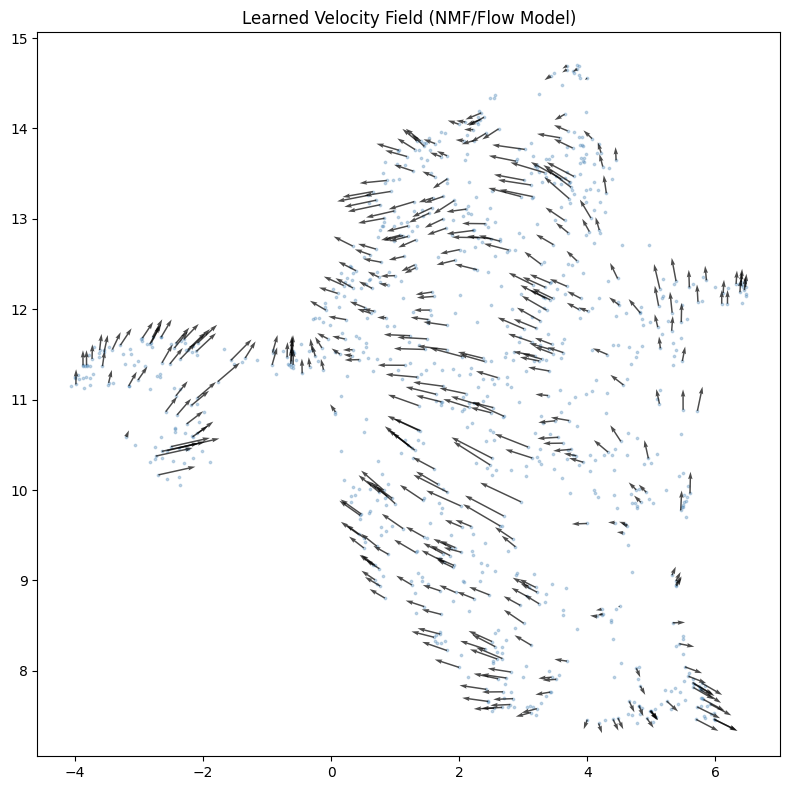

Velocity–pseudotime alignment: 0.08794615547597748


In [57]:
# visualize_velocity.py (UPDATED FOR LEARNED MODEL)

import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

# =========================
# 1. LOAD DATA
# =========================
adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("uv_leading/V_pred_learned.npy")   # <-- UPDATED NAME
gene_idx = np.load("gene_idx.npy")

X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

# =========================
# 2. ALIGN X TO MODEL SPACE
# =========================
X = X_full[:, gene_idx]

assert X.shape == V_pred.shape, "Mismatch between X and V_pred"

# =========================
# 3. UMAP EMBEDDING
# =========================
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# =========================
# 4. PROJECT VELOCITY TO UMAP
# =========================
eps = 0.5

X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# =========================
# 5. SMOOTH VELOCITY FIELD
# =========================
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# =========================
# 6. PLOT VECTOR FIELD
# =========================
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Learned Velocity Field (NMF/Flow Model)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

# =========================================================
# 7. FIXED CORRELATION (IMPORTANT — YOUR OLD ONE WAS WRONG)
# =========================================================

# WRONG BEFORE:
# spearmanr(pseudotime, dot(V, X[i+1] - X[i]))

# CORRECT IDEA:
# does velocity align with actual transitions in pseudotime ordering?

pseudo = adata.obs["facs_pseudotime"].values

# sort by pseudotime
order = np.argsort(pseudo)

X_sorted = X[order]
V_sorted = V_pred[order]

# finite differences along trajectory
dX = X_sorted[1:] - X_sorted[:-1]
V_mid = V_sorted[:-1]

# alignment score (cosine-like dot product)
alignment = np.sum(V_mid * dX, axis=1)

score = spearmanr(pseudo[order][:-1], alignment)[0]

print("Velocity–pseudotime alignment:", score)

In [66]:
# Metrics

from sklearn.metrics import r2_score
from scipy.stats import spearmanr
import scvelo as scv

# Metric A: Cross-boundary direction correctness (CBDir)
# Requires cell type labels. Measures whether velocity points from 
# progenitor clusters toward differentiated clusters.

adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

# scv.tl.velocity_graph(adata)  # uses your V_pred stored in adata.layers['velocity']
# scv.tl.velocity_confidence(adata)
# print(adata.obs['velocity_confidence'].mean())  # higher = more consistent field

# Metric B: velocity graph transition entropy
# A good velocity field should produce low-entropy transitions 
# (cells confidently point one direction, not scattered)
# scv.tl.velocity_graph(adata)
# Inspect adata.uns['velocity_graph'] — row entropy tells you confidence

# Metric C: correlation with RNA-based pseudotime (DPT) 
# as an internal consistency check separate from FACS
from scipy.stats import spearmanr
dpt_corr = spearmanr(adata.obs['dpt_pseudotime'], 
                      adata.obs['facs_pseudotime'])[0]
print("DPT-FACS agreement:", dpt_corr)  # sanity check your pseudotime labels

# Metric D: per-cell consistency (your best unsupervised metric)
# Does velocity at cell i agree with velocity at its neighbors?
def velocity_consistency(V_pred, nn_idx):
    scores = []
    for i in range(len(V_pred)):
        nbr_v = V_pred[nn_idx[i]]  # (K, G)
        v_i = V_pred[i]            # (G,)
        cos = (nbr_v @ v_i) / (
            np.linalg.norm(nbr_v, axis=1) * np.linalg.norm(v_i) + 1e-8
        )
        scores.append(cos.mean())
    return np.array(scores)

consistency = velocity_consistency(V_pred, idx)
print("Mean velocity consistency:", consistency.mean())
# This is fully unsupervised — no pseudotime needed

DPT-FACS agreement: 0.39182819939137054
Mean velocity consistency: 0.9138645


In [58]:
cos_sim = np.sum(V_mid * dX, axis=1) / (
    np.linalg.norm(V_mid, axis=1) * np.linalg.norm(dX, axis=1) + 1e-8
)

print("Mean velocity alignment:", np.mean(cos_sim))

Mean velocity alignment: 0.15382391


In [11]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

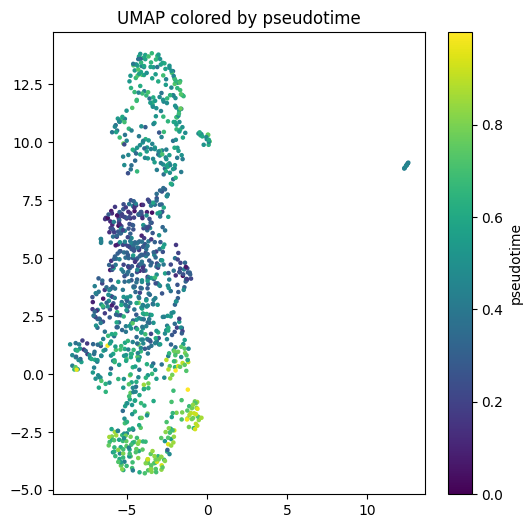

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(X_umap[:,0], X_umap[:,1], c=adata.obs["facs_pseudotime"], s=5)
plt.colorbar(label="pseudotime")
plt.title("UMAP colored by pseudotime")
plt.show()

In [59]:
from scipy.stats import spearmanr

score = spearmanr(
    adata.obs["facs_pseudotime"],
    np.linalg.norm(V_pred, axis=1)
)[0]

print(score)

0.033660414915473405


In [60]:
score = spearmanr(
    adata.obs["facs_pseudotime"],
    (V_pred * X).sum(axis=1)
)[0]
print(score)

-0.10203938251102873


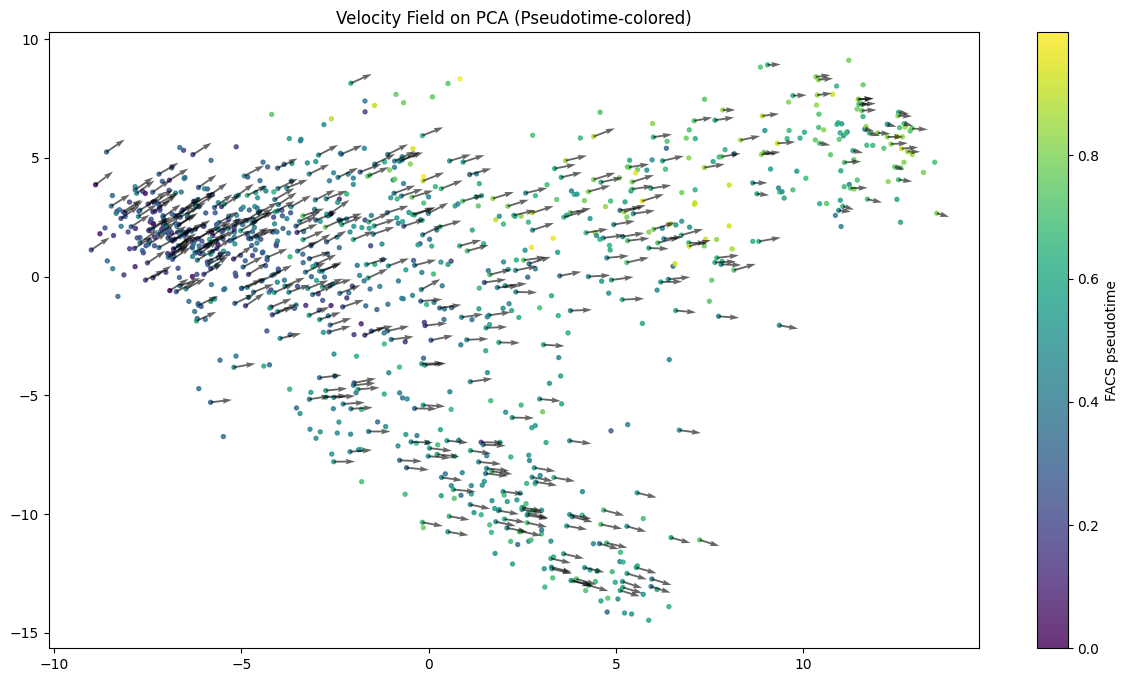

In [61]:
X_pca = adata.obsm["X_pca"][:, :10]  # use first PCs# linear projection of gene velocity into PCA space
V_pca = V_pred @ pca.components_.T[:, :10]
V_pca = -V_pca

from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
_, idx = nn.kneighbors(X_pca)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth = V_pca_smooth / (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)
V_pca_smooth *= 0.5

import numpy as np
import matplotlib.pyplot as plt

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_pca), 400, replace=False)

ax.quiver(
    X_pca[sample, 0], X_pca[sample, 1],
    V_pca_smooth[sample, 0], V_pca_smooth[sample, 1],
    color="black", alpha=0.6, scale=20, width=0.002
)

ax.set_title("Velocity Field on PCA (Pseudotime-colored)")
plt.show()

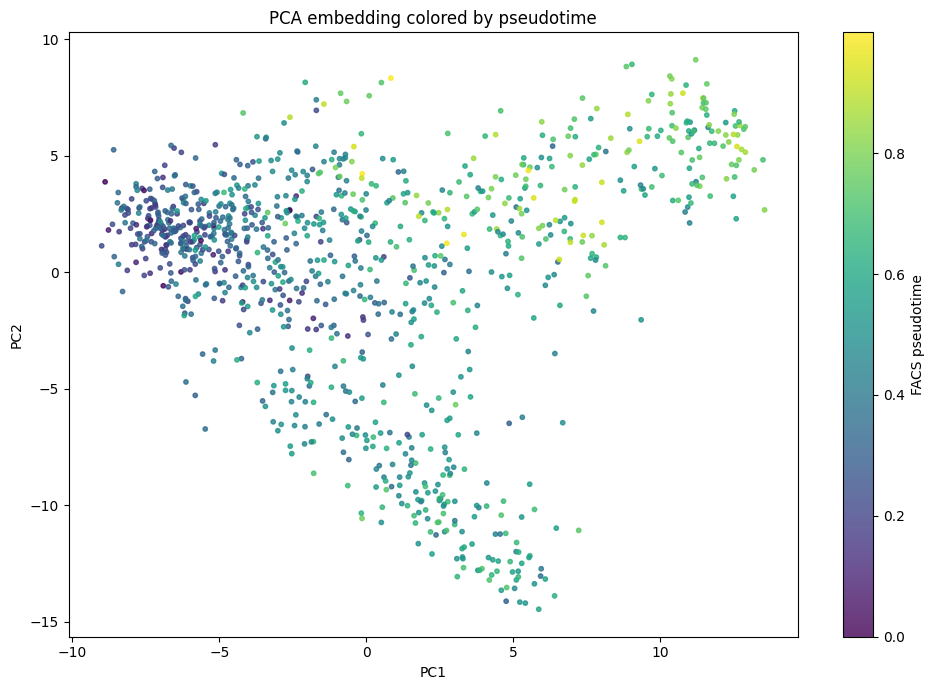

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# PCA embedding
X_pca = adata.obsm["X_pca"][:, :2]

# pseudotime (or swap for any obs label)
pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=10,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA embedding colored by pseudotime")

plt.tight_layout()
plt.show()

In [62]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

N = X.shape[0]

nn = NearestNeighbors(n_neighbors=30).fit(X)
neighbors = nn.kneighbors(X, return_distance=False)

def flow_alignment(V_pred, X, neighbors):
    N = X.shape[0]
    scores = []

    for i in range(N):
        vi = V_pred[i]
        vi_norm = np.linalg.norm(vi) + 1e-8

        for j in neighbors[i]:
            dx = X[j] - X[i]

            score = np.dot(vi, dx) / (
                vi_norm * (np.linalg.norm(dx) + 1e-8)
            )
            scores.append(score)

    return np.mean(scores)

score_forward = flow_alignment(V_pred, X, neighbors)
score_backward = flow_alignment(-V_pred, X, neighbors)

print("forward:", score_forward)
print("backward:", score_backward)

forward: 0.2708194
backward: -0.2708194
